# Lab - EDA Univariate Analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('./data/raw/amz_uk_price_prediction_dataset.csv')
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


### Dataset info

In [3]:
# print('shape:\n')
# print(df.shape)
# print('\ncolumns and types:\n')
# print(df.info())
# print('\nsummary statistics:\n')
# print(df.describe())

## Part 1: Understanding Product Categories
What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

### 1.1 Frequency Tables
- Generate a frequency table for the product `category`
- Which are the top 5 most listed product categories?

In [4]:
# check count for each product in category column
category_count = df['category'].value_counts()
top_5_categories = category_count.head(5)

print('Top 5 most listed product categories:\n')
print(top_5_categories)

Top 5 most listed product categories:

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


In [5]:
# frequency percentage table
frequency_table = pd.DataFrame({
    'Count': df['category'].value_counts(),
    'Percentage': df['category'].value_counts(normalize=True) * 100
})

print(frequency_table)

                                         Count  Percentage
category                                                  
Sports & Outdoors                       836265   34.221949
Beauty                                   19312    0.790293
Handmade Clothing, Shoes & Accessories   19229    0.786896
Bath & Body                              19092    0.781290
Birthday Gifts                           18978    0.776625
...                                        ...         ...
Alexa Built-In Devices                     107    0.004379
Motorbike Chassis                          107    0.004379
Plugs                                      107    0.004379
Smart Home Security & Lighting             104    0.004256
Smart Speakers                              54    0.002210

[296 rows x 2 columns]


### 1.2 Visualizations
- Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

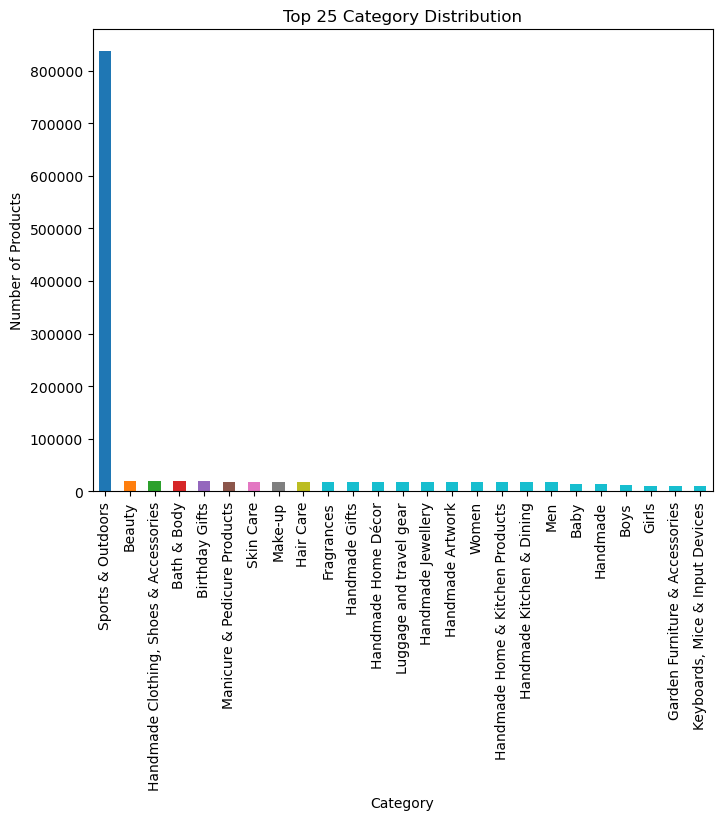

In [6]:
top_25_categories = category_count.head(25)

colors = plt.cm.tab10(range(len(top_25_categories))) #get 25 colors

# bar chart
top_25_categories.plot(kind='bar', color=colors, figsize=(8, 6))

plt.title('Top 25 Category Distribution')
plt.xlabel('Category')
plt.ylabel('Number of Products')

plt.show()

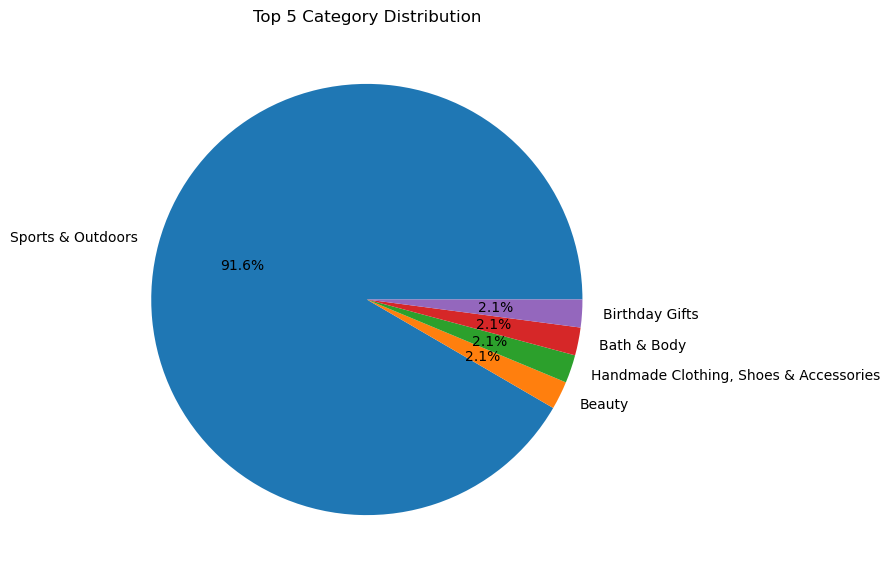

In [7]:
# pie chart of top categories
top_5_categories.plot(kind='pie', autopct='%1.1f%%', figsize=(7, 7))
plt.title('Top 5 Category Distribution')
plt.ylabel('')
plt.show()

### 2.1 Measures of Centrality
- Calculate the mean, median, and mode for the `price` of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [8]:
# mean, median and mode
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()

print(f'Mean Price: {mean_price}\nMedian Price: {median_price}\nMode Price: {mode_price}')

Mean Price: 89.24380943923663
Median Price: 19.09
Mode Price: 0    9.99
Name: price, dtype: float64


*Conclusion:*

    Skewed Distribution: The dataset appears to have a positive skew, meaning that there are a few products that are much more expensive than the rest, thus inflating the mean price.
    
    The mode (£9.99) and median (£19.09) suggest that most products are priced much lower, with £9.99 being the most frequent price point.
    
    The high mean (£89.24) is likely influenced by a small number of high-priced products.

### 2.2 Measures of Dispersion
- Determine the variance, standard deviation, range, and interquartile range for product `price`.
- How varied are the product prices? Are there any indicators of a significant spread in prices?

In [9]:
# Variance measures the spread of the prices around the mean.
price_variance = df['price'].var()

# Standard Deviation is the square root of the variance and tells you how spread out the prices are in the same units as the data.
price_std_dev = df['price'].std()

# Range is the difference between the maximum and minimum values in the dataset.
price_range = df['price'].max() - df['price'].min()

# Interquartile Range (IQR) is the range between the 25th percentile (Q1) and the 75th percentile (Q3), representing the middle 50% of the data.
price_Q1 = df['price'].quantile(0.25)  # 25th percentile
price_Q3 = df['price'].quantile(0.75)  # 75th percentile
price_IQR = price_Q3 - price_Q1

print(f'Price Variance: {price_variance:.2f}')
print(f'Price Standard Deviation: {price_std_dev:.2f}')
print(f'Price Range: {price_range:.2f}')
print(f'Price Interquartile Range (IQR): {price_IQR:.2f}')

Price Variance: 119445.49
Price Standard Deviation: 345.61
Price Range: 100000.00
Price Interquartile Range (IQR): 36.00


*Conclusion:*

    High Price Variation: The data shows significant spread in product prices. There are likely some very high-priced items (luxury products, niche items) that are pushing the variance, standard deviation, and range upward.
    
    Outliers: The wide range of £100,000 suggests the presence of outliers, meaning there are probably a small number of products that are priced significantly higher than the rest, influencing the mean and spreading the price distribution.
    
    Middle 50% Concentration: Despite the large range, the IQR of £36 suggests that the majority of products are clustered around a relatively narrow price range, implying that most products are within a similar pricing band.

In short, there is a **high degree of variability** in product prices, and the presence of outliers (extremely high-priced items) is the main factor contributing to the large spread in prices. However, for the majority of products, the prices are not that different from one another.

### 2.3 Visualizations
- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [17]:
print(df['price'].unique())

[ 21.99  23.99  31.99 ... 358.42 341.67 317.34]


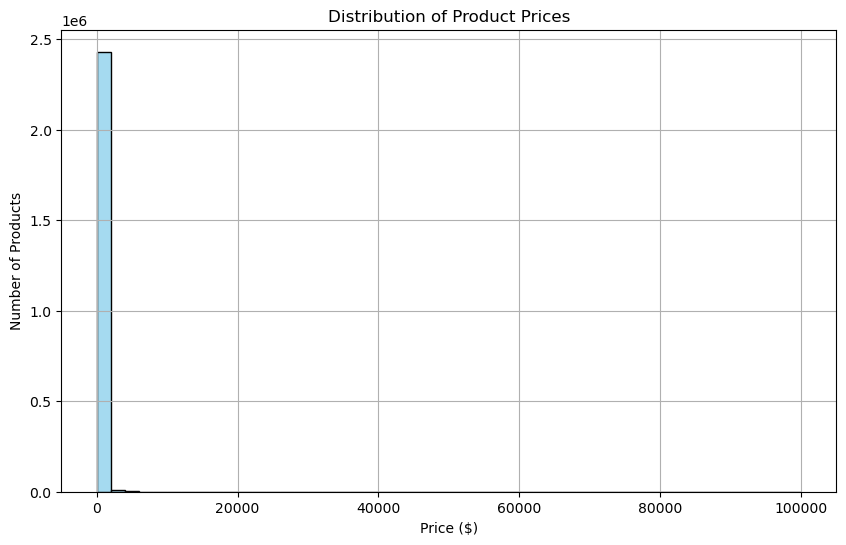

In [15]:
# product price distribution - histogram
plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=50, kde=False, color='skyblue', edgecolor='black')
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.grid(True)
plt.show()

In [ ]:
# histogram for products below £300

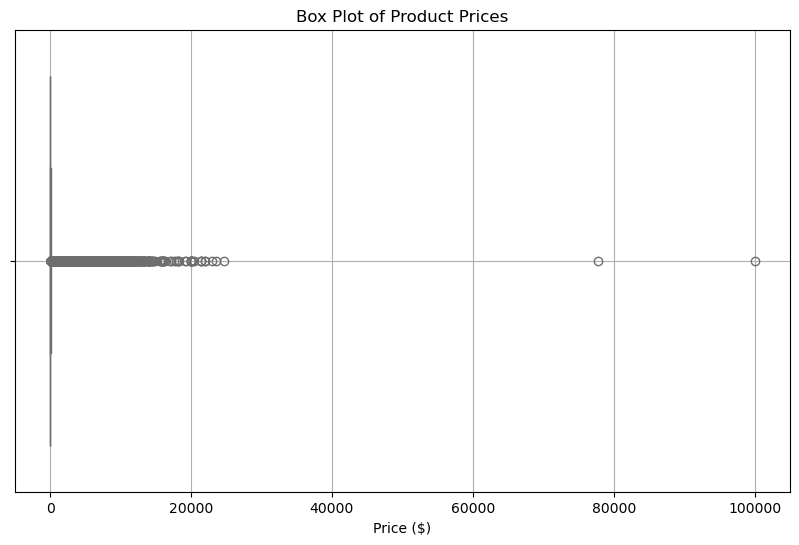

In [16]:
# box plot to showcase the spread and potential outliers in product pricing.

plt.figure(figsize=(10,6))
sns.boxplot(x=df['price'], color='lightcoral')
plt.title('Box Plot of Product Prices')
plt.xlabel('Price (£)')
plt.grid(True)
plt.show()

## Part 3: Unpacking Product Ratings
How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

### 3.1 Measures of Centrality
- Calculate the mean, median, and mode for the `rating` of products.
- How do customers generally rate products? Is there a common trend?

In [11]:
# mean, median and mode
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()

print(f'Mean Rating: {mean_rating}\nMedian Rating: {median_rating}\nMode Rating: {mode_rating}')

Mean Rating: 2.152836472966065
Median Rating: 0.0
Mode Rating: 0    0.0
Name: stars, dtype: float64


### 3.2 Measures of Dispersion
- Determine the variance, standard deviation, and interquartile range for product `rating`.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [12]:
# Variance measures the spread of the prices around the mean.
rating_variance = df['stars'].var()

# Standard Deviation is the square root of the variance and tells you how spread out the prices are in the same units as the data.
rating_std_dev = df['stars'].std()

# Range is the difference between the maximum and minimum values in the dataset.
rating_range = df['stars'].max() - df['stars'].min()

# Interquartile Range (IQR) is the range between the 25th percentile (Q1) and the 75th percentile (Q3), representing the middle 50% of the data.
rating_Q1 = df['stars'].quantile(0.25)  # 25th percentile
rating_Q3 = df['stars'].quantile(0.75)  # 75th percentile
rating_IQR = rating_Q3 - rating_Q1

print(f'Rating Variance: {rating_variance:.2f}')
print(f'Rating Standard Deviation: {rating_std_dev:.2f}')
print(f'Rating Range: {rating_range:.2f}')
print(f'Rating Interquartile Range (IQR): {rating_IQR:.2f}')

Rating Variance: 4.82
Rating Standard Deviation: 2.19
Rating Range: 5.00
Rating Interquartile Range (IQR): 4.40


### 3.3 Shape of the Distribution
- Calculate the skewness and kurtosis for the `rating` column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [13]:
## code

### 3.4 Visualizations
- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [14]:
## code